In [181]:
pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 79.9 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [rioxarray]
Note: you may need to restart the kernel to use updated packages.


In [182]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rioxarray as rxr
import xarray as xr

In [166]:
Adistans_dir = Path(
    "/home/jovyan/BIO597-SpatialBiodiversity/docs/project"
)

Adistans_raw = gpd.read_file(
    Adistans_dir / "Adistans_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Adistans_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Adistans_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Adistans_raw.shape)

(11863, 51)


In [167]:

# Read USA boundary
USA_boundary = gpd.read_file(
    Adistans_dir / "cb_2018_us_nation_5m.shp"
)

# Inspect
print(USA_boundary.shape)
print(USA_boundary.crs)
USA_boundary = USA_boundary.dissolve()



(1, 4)
EPSG:4269


In [168]:
Adistans_raw["species"].value_counts(dropna=False).head(20)

species
Aulacoseira distans    11863
Name: count, dtype: int64

In [169]:
Adistans_clean = Adistans_raw.dropna(subset=["decimalLatitude", "decimalLongitude"]).copy()
Adistans_clean.shape

(11265, 51)

In [170]:
Adistans_clean["coordinateUncertaintyInMeters"].value_counts(dropna=False).head(15)

coordinateUncertaintyInMeters
NaN          10546
50.0           249
10.0           196
5.0             95
1000.0          70
70.0            47
7.0             12
0.1              9
1.0              6
250.0            6
99.0             5
3525.0           5
400.0            4
7071.1           2
1105902.0        2
Name: count, dtype: int64

In [171]:
Adistans_clean = Adistans_clean[Adistans_clean["coordinateUncertaintyInMeters"].isna()
    |(Adistans_clean["coordinateUncertaintyInMeters"] <= 1000)
].copy()

Adistans_clean.shape

(11249, 51)

In [172]:
Adistans_clean = Adistans_clean.drop_duplicates(
    subset=["species", "decimalLatitude", "decimalLongitude", "year"]
).copy()

Adistans_clean.shape

(1474, 51)

In [173]:
Adistans_clean.explore()

In [174]:
USA_boundary = USA_boundary.to_crs(Adistans_clean.crs)

# Clip occurrences to USA boundary
Adistans_USA = gpd.clip(
    Adistans_clean,
    USA_boundary
)

print("Original records:", len(Adistans_clean))
print("USA records:", len(Adistans_USA))

Original records: 1474
USA records: 39


In [175]:
Adistans_USA.explore()

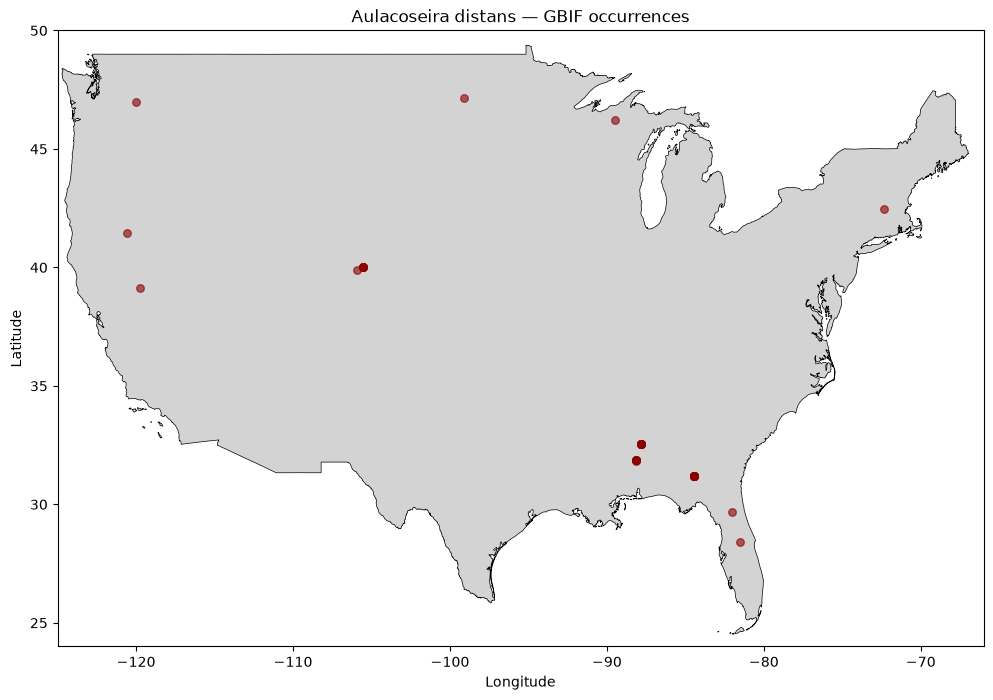

In [198]:
fig, ax = plt.subplots(figsize=(12, 8))

# USA boundary
USA_boundary.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

# Aulacoseira distans occurrences
Adistans_USA.plot(
    ax=ax,
    color="darkred",
    markersize=30,
    alpha=0.6
)

# Focus on contiguous USA
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Aulacoseira distans — GBIF occurrences")

plt.show()

In [178]:
#Bioclim

In [193]:
bioclim_path = Path("/home/jovyan/shared/bioclim")

bio1 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_1.tif",
    masked=True,
)

bio12 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_12.tif",
    masked=True,
)



In [194]:
bio1_USA = bio1.rio.clip(
    USA_boundary.geometry,
    USA_boundary.crs,
    drop=True,
    from_disk=True,
)

bio1_USA = bio1_USA.squeeze()

bio12_USA = bio12.rio.clip(
    USA_boundary.geometry,
    USA_boundary.crs,
    drop=True,
    from_disk=True,
)

bio12_USA = bio12_USA.squeeze()

In [195]:
print(Adistans_USA.crs)
print(bio1_USA.rio.crs)
print(bio12_USA.rio.crs)

EPSG:4326
EPSG:4326
EPSG:4326


In [187]:
point_x = xr.DataArray(
    Adistans_USA.geometry.x.to_numpy(),
    dims="record",
)

point_y = xr.DataArray(
    Adistans_USA.geometry.y.to_numpy(),
    dims="record",
)

In [196]:
bio1_values = bio1_USA.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

Adistans_USA["bio1_mean_temp_c"] = bio1_values

bio12_values = bio12_USA.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

Adistans_USA["bio12_annual_precip_mm"] = bio12_values
Adistans_USA.head()


,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,...,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue,geometry,bio1_mean_temp_c,bio12_annual_precip_mm
1545,4901535531,50c9509d-22c7-4a22-a47d-8c48425ef4a7,https://www.inaturalist.org/observations/22164...,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,Isabelle Rytlewski,Isabelle Rytlewski,,,2026-09-11T05:16:36.264Z,StillImage,CONTINENT_DERIVED_FROM_COORDINATES;TAXON_ID_NO...,POINT (-81.51267 28.41014),22.226334,1229.0
65,6497901454,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:1898bbe2-1c78-42ea-8a49-16a4381c5832,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,,NEON Technician,,,2026-09-10T00:09:29.486Z,,CONTINENT_DERIVED_FROM_COORDINATES;AMBIGUOUS_I...,POINT (-82.01457 29.68648),20.443167,1296.0
35,6497952588,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:d4434acf-ac9f-4741-a38e-dcfb57b23569,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,,NEON Technician,,,2026-09-10T00:09:31.082Z,,CONTINENT_DERIVED_FROM_COORDINATES;AMBIGUOUS_I...,POINT (-84.44105 31.18191),19.109333,1354.0
61,6497903786,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:4055b915-6ef1-4948-8b7d-7935a82979e4,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,,NEON Technician,,,2026-09-10T00:09:27.941Z,,CONTINENT_DERIVED_FROM_COORDINATES;AMBIGUOUS_I...,POINT (-84.44158 31.18265),19.109333,1354.0
14,6498022005,ca857858-61fd-4002-a201-c3530f781027,uuid:95c35d54-7be0-4142-9ac9-a86eddef408d,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,,NEON Technician,,,2026-09-09T23:54:25.117Z,,CONTINENT_DERIVED_FROM_COORDINATES;AMBIGUOUS_I...,POINT (-84.44158 31.18265),19.109333,1354.0


In [192]:
Adistans_USA.bio1_mean_temp_c.describe()

count    39.000000
mean     13.633667
std       7.834194
min      -9.602333
25%       8.155166
50%      17.773001
75%      19.109333
max      22.226334
Name: bio1_mean_temp_c, dtype: float64

In [197]:
Adistans_USA.bio12_annual_precip_mm.describe()

count      39.000000
mean     1101.333333
std       443.884429
min       181.000000
25%       567.000000
50%      1354.000000
75%      1400.000000
max      1513.000000
Name: bio12_annual_precip_mm, dtype: float64